# SPHEREx Shift-and-Stack: finding moving objects that no single image can show

**NASA Space Apps Challenge 2026: Planet X and SPHEREx**

Existing tools ask people to find what is visible. This pipeline finds faint moving objects that are invisible in every individual SPHEREx exposure, rejects artifacts automatically, and estimates what each object is from its colors.

**Pipeline**
1. **Find:** shift-and-stack. For many possible velocities, shift all exposures as if tracking a moving object and add them up. Noise averages out; an object moving at that velocity adds up into a clear point.
2. **Verify:** automatic checks (image edges, residuals of bright stars, signal present in both halves of the observations), plus injection-recovery tests with artificial objects to measure sensitivity.
3. **Understand:** each SPHEREx detector sees a different wavelength, so measuring brightness along the found track gives a 6-color spectrum for free.

**How to run:** in section 1 set `NAME` to one of the targets (or add your own field), then Runtime → Run all. Downloaded data are cached on Google Drive, so the archive is only queried once per field. Results are written to `spherex_site/data/<NAME>/fast` and `spherex_site/data/<NAME>/slow` on Drive; copy them into the repo under `site/data/`.

**To process any other field:** add a line to `TARGETS` with its coordinates (proper motion 0 if unknown), set `NAME` to it, and Run all.

**AI use:** code was written with the help of Claude (Anthropic).

**Lenses per target** (set in `TARGETS`): `fast` = Fast movers (sections 5–8), `slow` = Slow movers (section 9), `variable` = Blinking stars (section 10). Sections for lenses a target doesn't have are skipped automatically.

## 1. Setup

In [ ]:
!pip -q install astroquery reproject

In [ ]:
import os, json, time, warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.io import fits
from astropy.time import Time
from astropy.wcs import WCS
from astropy.visualization import ZScaleInterval
from astroquery.ipac.irsa import Irsa
from reproject import reproject_interp
from scipy.ndimage import binary_dilation, distance_transform_edt, maximum_filter
from matplotlib.animation import FuncAnimation, PillowWriter

from google.colab import drive
drive.mount("/content/drive", force_remount=True)

# ---- Targets ----
# name: field centre (ra, dec) used for the cutouts, then position + proper motion for Slow movers:
#       (ra0, dec0 at epoch ep0, pmra, pmdec in mas/yr). Use pm 0 if the object does not move.
# The field centres of barnard and wise0855 must stay as they are: their cached data were made with them.
TARGETS = {
    "barnard":  dict(field=(269.448, 4.770),        star=(269.448503, 4.739420, 2016.0, -801.551, 10362.394),
                     name="Barnard's Star", modes=["fast", "slow"]),
    "wise0855": dict(field=(133.780984, -7.243932), star=(133.7951, -7.2451, 2010.5, -8150.0, 670.0),
                     name="WISE 0855", modes=["fast", "slow"]),
    "epsindib": dict(field=(331.096, -56.801),      star=(331.0438, -56.7827, 2000.0, 3966.7, -2536.2),
                     name="Epsilon Indi B", modes=["fast", "slow"]),
    "rwaur":    dict(field=(76.956, 30.401),        star=(76.9564, 30.4014, 2000.0, 0.0, 0.0),
                     name="RW Aurigae", modes=["variable"]),     # needs at least 2 passes downloaded (PASS = 1, 2)
    "rdra":     dict(field=(248.168, 66.755),       star=(248.1675, 66.7550, 2000.0, 0.0, 0.0),
                     name="R Draconis", modes=[]),               # saturated + deep-survey area: not supported yet
}

NAME = "rdra"               # <-- choose the target here
PASS = 2                        # survey pass to use: 0, 1 or 2
N, PIXEL_ARCSEC = 60, 6.15      # output grid: 60 x 60 pixels, SPHEREx pixel scale

FIELD_NAME = NAME
ra, dec = TARGETS[NAME]["field"]
MODES = TARGETS[NAME]["modes"]
DO_FAST = "fast" in MODES
print(f"Field: {TARGETS[NAME]['name']} ({NAME}), centre {ra}, {dec}, pass {PASS}, lenses: {MODES}")

DATA_DIR = "/content/drive/MyDrive/spherex_data"
OUT = "/content/drive/MyDrive/spherex_site"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive
Field: R Draconis (rdra), centre 248.168, 66.755, pass 2, lenses: []


## 2. Which SPHEREx exposures cover this field?

In [ ]:
query = f'''
SELECT a.uri, p.time_bounds_lower, p.energy_bandpassname
FROM spherex.artifact a
JOIN spherex.plane p ON a.planeid = p.planeid
WHERE 1 = CONTAINS(POINT('ICRS', {ra}, {dec}), p.poly)
ORDER BY p.time_bounds_lower
'''
res = Irsa.query_tap(query).to_table()
mjd = np.array(res["time_bounds_lower"], dtype=float)
print("Exposures covering the field:", len(res))

# Split into survey passes: a new pass starts after a gap of more than 30 days
visit = np.concatenate([[0], np.cumsum(np.diff(mjd) > 30)])
for v in np.unique(visit):
    m = mjd[visit == v]
    print(f"Pass {v}: {len(m)} exposures, "
          f"{Time(m.min(), format='mjd').iso[:10]} to {Time(m.max(), format='mjd').iso[:10]}")
print("Exposures per detector:", dict(Counter(res["energy_bandpassname"])))

Exposures covering the field: 2493
Pass 0: 240 exposures, 2025-04-24 to 2025-07-22
Pass 1: 2253 exposures, 2025-08-29 to 2026-09-27
Exposures per detector: {'SPHEREx-D6': 573, 'SPHEREx-D3': 574, 'SPHEREx-D4': 584, 'SPHEREx-D1': 584, 'SPHEREx-D5': 89, 'SPHEREx-D2': 89}


## 3. Download cutouts and align them on one sky grid (cached on Drive)

Loaded from Drive: /content/drive/MyDrive/spherex_data/rdra_pass2.npz
Aligned exposures: 0


IndexError: index 0 is out of bounds for axis 0 with size 0

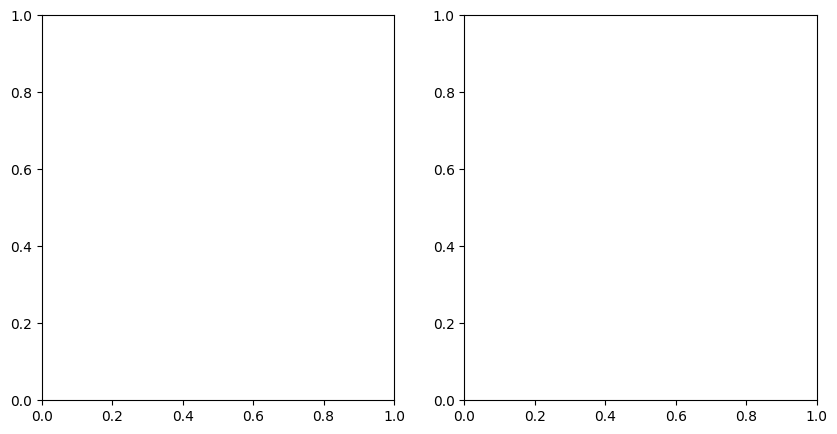

In [ ]:
# Common grid: north up, SPHEREx pixel scale
scale = PIXEL_ARCSEC / 3600
target = WCS(naxis=2)
target.wcs.ctype = ["RA---TAN", "DEC--TAN"]
target.wcs.crval = [ra, dec]
target.wcs.crpix = [N / 2 + 0.5, N / 2 + 0.5]
target.wcs.cdelt = [-scale, scale]

def load_aligned(row, size_deg=0.12):
    url = (f"https://irsa.ipac.caltech.edu/{str(row['uri']).lstrip('/')}"
           f"?center={ra},{dec}&size={size_deg}")
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            with fits.open(url, cache=False) as h:
                data = h["IMAGE"].data.astype(float)
                w = WCS(h["IMAGE"].header)
            img, _ = reproject_interp((data, w), target, shape_out=(N, N))
        return img - np.nanmedian(img)          # remove frame background
    except Exception as e:
        print("skipped:", str(e)[:80])
        return None

def load_retry(row, tries=5):
    for attempt in range(tries):
        img = load_aligned(row)
        if img is not None:
            return img
        time.sleep(5 * (attempt + 1))           # the archive is busy: wait longer each time
    return None

cache = f"{DATA_DIR}/{FIELD_NAME}_pass{PASS}.npz"
if os.path.exists(cache):
    with np.load(cache, allow_pickle=True) as d:
        cube, times, bands = d["cube"], d["times"], d["bands"].astype(str)
        if "center" in d and np.max(np.abs(d["center"] - np.array([ra, dec]))) > 1e-4:
            raise ValueError(f"Cached data were made for centre {d['center']}, not {ra}, {dec}. "
                             "Use the same centre or delete the cache file.")
    print("Loaded from Drive:", cache)
else:
    sel = visit == PASS
    rows, t_sel = res[sel], mjd[sel]
    with ThreadPoolExecutor(2) as ex:           # only 2 parallel downloads: the archive is busy
        imgs = list(ex.map(load_retry, rows))
    ok = [i for i, x in enumerate(imgs) if x is not None]
    cube = np.array([imgs[i] for i in ok])
    times = t_sel[ok]
    bands = np.array(rows["energy_bandpassname"]).astype(str)[ok]
    np.savez(cache, cube=cube, times=times, bands=bands, center=np.array([ra, dec]))
    print("Saved to Drive:", cache)
print("Aligned exposures:", len(cube))

stack = np.nanmedian(cube, axis=0)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, img, title in [(axes[0], cube[0], "single exposure"),
                       (axes[1], stack, f"median of {len(cube)} exposures")]:
    lo, hi = ZScaleInterval().get_limits(img)
    ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set_title(title)
plt.show()

## 4. Core functions: injection, preparation, shift-and-stack

In [ ]:
def mad_std(a):
    # Robust noise estimate that ignores stars and outliers
    return 1.4826 * np.nanmedian(np.abs(a - np.nanmedian(a)))

def inject(cube, times, x0, y0, vx, vy, amp_sigma=1.5, psf_sigma=0.8):
    # Add an artificial moving object: start (x0, y0), velocity in pixels/day,
    # brightness in units of the single-exposure noise.
    out = cube.copy()
    yy, xx = np.mgrid[:cube.shape[1], :cube.shape[2]]
    dt = times - times.min()
    for k in range(len(cube)):
        x, y = x0 + vx * dt[k], y0 + vy * dt[k]
        psf = np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * psf_sigma ** 2))
        out[k] += amp_sigma * mad_std(cube[k]) * psf
    return out

def prepare(cube, bands, clip=5.0, mask=None):
    z = np.full_like(cube, np.nan)
    # 1. Static-sky template per detector (each detector sees a different color)
    for b in np.unique(bands):
        sel = bands == b
        z[sel] = cube[sel] - np.nanmedian(cube[sel], axis=0)
    # 2. Mask bright stars (or use a given mask, so artificial objects never mask themselves)
    if mask is None:
        template = np.nanmedian(cube, axis=0)
        mask = binary_dilation(template > 5 * mad_std(template), iterations=1)
    z[:, mask] = np.nan
    # 3. Normalise noise to 1 and drop bad exposures
    s = np.array([mad_std(f) for f in z])
    filled = np.mean(np.isfinite(z), axis=(1, 2))
    good = np.isfinite(s) & (s > 0) & (filled > 0.3)
    z = z[good] / s[good, None, None]
    # 4. Clip cosmic rays and hot pixels
    z = np.clip(z, -clip, clip)
    return z, mask, good

def shift_img(img, dy, dx):
    # Shift without wrapping around the edges; empty pixels become NaN
    H, W = img.shape
    out = np.full_like(img, np.nan)
    if abs(dy) >= H or abs(dx) >= W:
        return out
    out[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = \
        img[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
    return out

def shift_stack_ref(z, times, vx, vy, t_ref):
    # Shift exposures against the assumed motion and add them.
    # Output: significance map, positions given at time t_ref.
    dt = times - t_ref
    acc = np.zeros(z.shape[1:]); n = np.zeros(z.shape[1:])
    for k in range(len(z)):
        f = shift_img(z[k], int(round(-vy * dt[k])), int(round(-vx * dt[k])))
        acc += np.nan_to_num(f); n += np.isfinite(f)
    out = acc / np.sqrt(np.maximum(n, 1))
    out[n < 0.5 * len(z)] = np.nan                                  # too few exposures
    out[:3, :] = out[-3:, :] = out[:, :3] = out[:, -3:] = np.nan    # image edges
    return out

def shift_stack(z, times, vx, vy):
    return shift_stack_ref(z, times, vx, vy, times.min())

def clean_start(vx, vy, mask, T, seed=0):
    # Start position whose whole track stays inside the image and well away from bright-star masks
    # (tries a wide safety margin first, then smaller ones in crowded fields)
    for margin in (4, 3, 2):
        rng_ = np.random.default_rng(seed)
        wide = binary_dilation(mask, iterations=margin)
        for _ in range(3000):
            x0, y0 = rng_.uniform(6, N - 6, 2)
            xs = x0 + vx * np.linspace(0, T, 25); ys = y0 + vy * np.linspace(0, T, 25)
            if xs.min() < 5 or xs.max() > N - 6 or ys.min() < 5 or ys.max() > N - 6:
                continue
            if not wide[np.round(ys).astype(int), np.round(xs).astype(int)].any():
                return round(float(x0), 1), round(float(y0), 1)
    raise RuntimeError("No clean track found in this field: try smaller velocities")

vs = np.arange(-0.5, 0.51, 0.05)   # velocity grid, pixels/day
T_all = times.max() - times.min()  # time span of the pass, days
_, mask_all, _ = prepare(cube, bands)

## 5. Test: can the pipeline find an injected object that is invisible in single exposures?

In [ ]:
if not DO_FAST:
    print(f"{NAME}: no Fast movers lens, section skipped.")
else:
    true_vx, true_vy = 0.25, -0.10
    x0, y0 = clean_start(true_vx, true_vy, mask_all, T_all, seed=0)   # a track on clean sky
    fake = inject(cube, times, x0, y0, true_vx, true_vy)
    z, mask, good = prepare(fake, bands, mask=mask_all)
    tz = times[good]
    print("Exposures after quality cuts:", len(z), "of", len(cube))

    best = np.array([[np.nanmax(shift_stack(z, tz, vx, vy)) for vx in vs] for vy in vs])
    iy, ix = np.unravel_index(np.nanargmax(best), best.shape)
    img = shift_stack(z, tz, vs[ix], vs[iy])
    py, px = np.unravel_index(np.nanargmax(img), img.shape)
    print(f"Found: vx={vs[ix]:.2f}, vy={vs[iy]:.2f}, significance {np.nanmax(best):.1f}, position ({px}, {py})")
    print(f"True:  vx={true_vx}, vy={true_vy}, position ({x0:.0f}, {y0:.0f})")

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    axes[0].imshow(z[0], origin="lower", cmap="gray", vmin=-3, vmax=5)
    axes[0].set_title("single exposure")
    axes[1].imshow(shift_stack(z, tz, 0, 0), origin="lower", cmap="gray", vmin=-3, vmax=8)
    axes[1].set_title("plain stack")
    axes[2].imshow(img, origin="lower", cmap="gray", vmin=-3, vmax=8)
    axes[2].plot(px, py, "r+", ms=15)
    axes[2].set_title("stack along found motion")
    im = axes[3].imshow(best, origin="lower", extent=[vs[0], vs[-1], vs[0], vs[-1]])
    axes[3].set_title("significance per velocity")
    axes[3].set_xlabel("vx, pixels/day"); axes[3].set_ylabel("vy, pixels/day")
    plt.colorbar(im, ax=axes[3])
    plt.show()

## 6. Brightest candidate in the real data (no injected objects)

In [ ]:
if not DO_FAST:
    print(f"{NAME}: no Fast movers lens, section skipped.")
else:
    z0, mask0, g0 = prepare(cube, bands)
    t0, b0 = times[g0], bands[g0]
    tref = t0.min()

    noise0 = np.array([[np.nanmax(shift_stack_ref(z0, t0, vx, vy, tref)) for vx in vs] for vy in vs])
    iy0, ix0 = np.unravel_index(np.nanargmax(noise0), noise0.shape)
    cvx, cvy = vs[ix0], vs[iy0]
    cimg = shift_stack_ref(z0, t0, cvx, cvy, tref)
    cy, cx = np.unravel_index(np.nanargmax(cimg), cimg.shape)
    print(f"Candidate: position ({cx}, {cy}), velocity ({cvx:.2f}, {cvy:.2f}) pixels/day "
          f"= {np.hypot(cvx, cvy) * PIXEL_ARCSEC:.1f} arcsec/day, significance {cimg[cy, cx]:.1f}")
    print("Distance to nearest star mask:", round(distance_transform_edt(~mask0)[cy, cx], 1), "pixels")

    def sig_at(idx):
        im = shift_stack_ref(z0[idx], t0[idx], cvx, cvy, tref)
        return np.nanmax(im[max(cy - 1, 0):cy + 2, max(cx - 1, 0):cx + 2])

    order = np.argsort(t0)
    h = len(order) // 2
    s_all = cimg[cy, cx]
    print(f"Halves in time (a real object gives ~{s_all / 1.41:.1f} in both): "
          f"{sig_at(order[:h]):.1f} and {sig_at(order[h:]):.1f}")
    print(f"Per detector (a real object is spread out, ~{s_all / 2.45:.1f} each):",
          {str(b)[-2:]: round(float(sig_at(np.where(b0 == b)[0])), 1) for b in np.unique(b0)})

    try:
        from astroquery.imcce import Skybot
        r = Skybot.cone_search(target.pixel_to_world(cx, cy), 2 * u.arcmin, Time(tref, format="mjd"))
        print("Known Solar System objects nearby:"); print(r[:5])
    except Exception as e:
        print("SkyBoT:", str(e)[:120])

    fig, ax = plt.subplots(1, 2, figsize=(9, 4))
    for a, im, ttl in [(ax[0], shift_stack_ref(z0, t0, 0, 0, tref), "plain stack"),
                       (ax[1], cimg, "stack along candidate motion")]:
        a.imshow(im, origin="lower", cmap="gray", vmin=-3, vmax=8)
        a.plot(cx, cy, "r+", ms=15); a.set_title(ttl)
    plt.show()

## 7. Detection threshold and sensitivity (injection-recovery test)

In [ ]:
if not DO_FAST:
    print(f"{NAME}: no Fast movers lens, section skipped.")
else:
    # 1. Remove the candidate's track and measure the real noise level
    zn = z0.copy()
    yy, xx = np.mgrid[:zn.shape[1], :zn.shape[2]]
    for k in range(len(zn)):
        dt = t0[k] - tref
        zn[k][(xx - (cx + cvx * dt)) ** 2 + (yy - (cy + cvy * dt)) ** 2 < 9] = np.nan
    noise = np.array([[np.nanmax(shift_stack_ref(zn, t0, vx, vy, tref)) for vx in vs] for vy in vs])
    thr = np.nanmax(noise)
    print(f"Detection threshold (brightest noise peak): {thr:.1f}")

    # 2. Inject objects whose whole track stays inside the image
    T = times.max() - times.min()
    rng = np.random.default_rng(1)
    amps = [2.0, 1.5, 1.0, 0.7, 0.5, 0.35]
    rates = []
    for a in amps:
        hits = valid = 0
        for _ in range(12):
            vx, vy = rng.uniform(-0.3, 0.3, 2)
            x0 = rng.uniform(max(5, 5 - vx * T), min(55, 55 - vx * T))
            y0 = rng.uniform(max(5, 5 - vy * T), min(55, 55 - vy * T))
            z, _, g = prepare(inject(cube, times, x0, y0, vx, vy, amp_sigma=a), bands, mask=mask_all)
            img = shift_stack_ref(z, times[g], vx, vy, times.min())
            xi, yi = int(round(x0)), int(round(y0))
            patch = img[max(yi - 1, 0):yi + 2, max(xi - 1, 0):xi + 2]
            if np.all(np.isnan(patch)):
                continue
            valid += 1; hits += np.nanmax(patch) > thr
        rates.append(100 * hits / max(valid, 1))
        print(f"brightness {a}: found {hits} of {valid}")

    plt.figure(figsize=(6, 4))
    plt.plot(amps, rates, "o-")
    plt.axvline(5, ls="--", color="gray", label="single-exposure limit (~5 sigma)")
    plt.xscale("log")
    plt.xticks([0.35, 0.5, 0.7, 1, 1.5, 2, 5], ["0.35", "0.5", "0.7", "1", "1.5", "2", "5"])
    plt.xlabel("object brightness, in units of single-exposure noise"); plt.ylabel("recovered, %")
    plt.title("Shift-and-stack sensitivity"); plt.legend(); plt.show()

## 8. Full automatic pipeline: candidates, checks, 6-color spectrum, files for the website

In [ ]:
if not DO_FAST:
    print(f"{NAME}: no Fast movers lens, section skipped.")
else:
    import shutil
    WAVE = {"D1": 0.93, "D2": 1.37, "D3": 2.03, "D4": 3.12, "D5": 4.13, "D6": 4.71}  # detector centre, microns
    OUT_FAST = f"{OUT}/data/{NAME}/fast"
    shutil.rmtree(OUT_FAST, ignore_errors=True)        # start clean: no files left from older runs
    os.makedirs(OUT_FAST, exist_ok=True)

    def inject_sed(cube, times, bands, x0, y0, vx, vy, factors, snr=3.0, psf_sigma=0.8):
        # Add an artificial object with its own color (factors = relative brightness per detector).
        # The overall brightness is scaled so that its average single-exposure signal-to-noise is `snr`:
        # invisible in any one image, but the color stays physically correct.
        out = cube.copy()
        noise_k = np.array([mad_std(f) for f in cube])
        fk = np.array([factors[str(b)[-2:]] for b in bands])
        amp = snr / np.mean(fk / noise_k)
        yy, xx = np.mgrid[:cube.shape[1], :cube.shape[2]]
        dt = times - times.min()
        for k in range(len(cube)):
            x, y = x0 + vx * dt[k], y0 + vy * dt[k]
            out[k] += amp * fk[k] * np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * psf_sigma ** 2))
        return out

    def find_candidates(z, t, thr, top=5):
        # Blind search: peaks above threshold for every velocity, duplicates removed
        tr, found = t.min(), []
        for vy in vs:
            for vx in vs:
                im = shift_stack_ref(z, t, vx, vy, tr)
                im2 = np.nan_to_num(im, nan=-99.0)
                pk = (im2 == maximum_filter(im2, size=5)) & (im2 > thr)
                for y, x in zip(*np.nonzero(pk)):
                    found.append(dict(x=int(x), y=int(y), vx=round(float(vx), 2),
                                      vy=round(float(vy), 2), sig=round(float(im[y, x]), 1)))
        found.sort(key=lambda c: -c["sig"])
        uniq = []
        for c in found:   # one object peaks at neighbouring velocities too: keep the strongest
            if all(np.hypot(c["x"] - q["x"], c["y"] - q["y"]) > 6 for q in uniq):
                uniq.append(c)
        return uniq[:top]

    def check(c, z, t, mask):
        # Automatic checks: significance in each half of the observations and rejection reasons
        tr = t.min()
        def s(idx):
            im = shift_stack_ref(z[idx], t[idx], c["vx"], c["vy"], tr)
            p = im[max(c["y"] - 1, 0):c["y"] + 2, max(c["x"] - 1, 0):c["x"] + 2]
            return round(float(np.nanmax(p)), 1) if np.isfinite(p).any() else 0.0
        o = np.argsort(t); h = len(o) // 2
        halves = [s(o[:h]), s(o[h:])]
        reasons = []
        if distance_transform_edt(~mask)[c["y"], c["x"]] < 2:
            reasons.append("next to a bright-star mask: likely a star residual")
        if min(halves) < 0.35 * c["sig"]:
            reasons.append("signal present in only one half of the observations")
        if c["sig"] < thr + 1:
            reasons.append("barely above the noise threshold: likely noise")
        return halves, reasons

    def sed(cube, t, b, c):
        # Brightness along the track, median per detector (6 colors)
        tr = t.min()
        d = np.full_like(cube, np.nan)
        for k in np.unique(b):
            sel = b == k
            d[sel] = cube[sel] - np.nanmedian(cube[sel], axis=0)
        out = {}
        for k in np.unique(b):
            f = []
            for i in np.where(b == k)[0]:
                x = int(round(c["x"] + c["vx"] * (t[i] - tr)))
                y = int(round(c["y"] + c["vy"] * (t[i] - tr)))
                if 1 <= x < cube.shape[2] - 1 and 1 <= y < cube.shape[1] - 1:
                    f.append(np.nansum(d[i, y - 1:y + 2, x - 1:x + 2]))
            out[str(k)[-2:]] = round(float(np.nanmedian(f)), 4) if f else None
        return out

    def classify(s):
        blue = [s[k] for k in ("D1", "D2") if s.get(k) is not None]
        red = [s[k] for k in ("D5", "D6") if s.get(k) is not None]
        if not blue or not red:
            return "not enough data for a color"
        b_, r_ = np.mean(blue), np.mean(red)
        if r_ > 0 and r_ > 3 * max(b_, 0):
            return "very red: similar to a cold brown dwarf or a distant cold body"
        return "normal color: similar to an asteroid in reflected sunlight, or a star"

    def save_visuals(cid, z, t, c):
        tr, X, Y = t.min(), c["x"], c["y"]
        crop = lambda im: im[max(Y - 12, 0):Y + 13, max(X - 12, 0):X + 13]
        o = np.argsort(t)
        panels = [crop(z[o[len(o) // 2]]),
                  crop(shift_stack_ref(z, t, 0, 0, tr)),
                  crop(shift_stack_ref(z, t, c["vx"], c["vy"], tr))]
        fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
        for a, im, ttl in zip(ax, panels, ["single exposure", "plain stack", "stack along motion"]):
            a.imshow(im, origin="lower", cmap="gray", vmin=-3, vmax=8); a.set_title(ttl); a.axis("off")
        plt.tight_layout(); fig.savefig(f"{OUT_FAST}/{cid}.png", dpi=110); plt.close(fig)
        # Animation: the object emerges as more exposures are added
        steps = np.linspace(6, len(o), 12).astype(int)
        fig, a = plt.subplots(figsize=(3.2, 3.4)); a.axis("off")
        art = a.imshow(panels[2], origin="lower", cmap="gray", vmin=-3, vmax=8)
        def upd(i):
            n = steps[i]
            art.set_data(crop(shift_stack_ref(z[o[:n]], t[o[:n]], c["vx"], c["vy"], tr)))
            a.set_title(f"exposures stacked: {n}")
            return [art]
        FuncAnimation(fig, upd, frames=len(steps)).save(f"{OUT_FAST}/{cid}.gif", writer=PillowWriter(fps=3))
        plt.close(fig)

    # --- Demo: two artificial objects with different colors, placed on clean sky ---
    DEMO = []
    for seed, (vx, vy, f) in enumerate([
            (0.25, -0.10, {"D1": 0.1, "D2": 0.3, "D3": 0.6, "D4": 1.5, "D5": 3.0, "D6": 3.0}),    # red
            (-0.20, 0.15, {"D1": 2.0, "D2": 1.8, "D3": 1.5, "D4": 1.2, "D5": 1.0, "D6": 1.0})]):  # normal
        x0, y0 = clean_start(vx, vy, mask_all, T_all, seed=seed + 1)
        DEMO.append(dict(x0=x0, y0=y0, vx=vx, vy=vy, f=f))
    print("Demo objects placed at:", [(d_["x0"], d_["y0"]) for d_ in DEMO])
    work = cube.copy()
    for d_ in DEMO:
        work = inject_sed(work, times, bands, d_["x0"], d_["y0"], d_["vx"], d_["vy"], d_["f"])

    # --- Full automatic pipeline ---
    z, m, g = prepare(work, bands, mask=mask_all)     # same star mask as the original data
    t, b, c3 = times[g], bands[g], work[g]
    cands = []
    for j, c in enumerate(find_candidates(z, t, thr)):
        cid = f"{FIELD_NAME}_cand_{j + 1}"
        halves, reasons = check(c, z, t, m)
        s = sed(c3, t, b, c)
        sky = target.pixel_to_world(c["x"], c["y"])
        is_demo = any(abs(c["x"] - d_["x0"]) <= 2 and abs(c["y"] - d_["y0"]) <= 2 for d_ in DEMO)
        save_visuals(cid, z, t, c)
        cands.append(dict(
            id=cid, demo=is_demo, ra=round(float(sky.ra.deg), 5), dec=round(float(sky.dec.deg), 5),
            date_ref=Time(t.min(), format="mjd").iso[:10], **c,
            speed_arcsec_day=round(float(np.hypot(c["vx"], c["vy"]) * PIXEL_ARCSEC), 2),
            halves=halves, verdict="candidate" if not reasons else "rejected", reasons=reasons,
            sed=s, sed_wave_um={k: WAVE[k] for k in s}, color_class=classify(s),
            image=f"{cid}.png", animation=f"{cid}.gif"))
        print(f"{cid}: ({c['x']}, {c['y']}), significance {c['sig']}, demo={is_demo}, "
              f"{cands[-1]['verdict']} {reasons if reasons else ''} | {cands[-1]['color_class']}")

    with open(f"{OUT_FAST}/candidates.json", "w", encoding="utf-8") as f:
        json.dump(dict(field=dict(name=FIELD_NAME, ra=ra, dec=dec,
                                  exposures=int(len(t)), threshold=round(float(thr), 1),
                                  dates=[Time(t.min(), format="mjd").iso[:10],
                                         Time(t.max(), format="mjd").iso[:10]]),
                       candidates=cands), f, ensure_ascii=False, indent=1)
    print("Saved to", OUT_FAST, ":", sorted(os.listdir(OUT_FAST)))
    n_demo = sum(c["demo"] and c["verdict"] == "candidate" for c in cands)
    print(f"{n_demo} of 2 demo objects recovered as candidates.")
    if n_demo < 2:
        print("WARNING: not all demo objects were recovered. Check the images before using these results.")

    plt.figure(figsize=(6, 4))
    for c in cands:
        ks = [k for k in WAVE if c["sed"].get(k) is not None]
        plt.plot([WAVE[k] for k in ks], [c["sed"][k] for k in ks], "o-",
                 label=f"{c['id']} ({'demo' if c['demo'] else c['verdict']})")
    plt.xlabel("wavelength, microns"); plt.ylabel("brightness, relative units")
    plt.title("6-color spectrum along the track"); plt.legend(); plt.show()

## 9. Slow movers (Time Machine): WISE 2010 vs SPHEREx 2026

In [ ]:
from astropy.coordinates import SkyCoord
from PIL import Image
import shutil
WAVE = {"D1": 0.93, "D2": 1.37, "D3": 2.03, "D4": 3.12, "D5": 4.13, "D6": 4.71}

ra0, dec0, EP0, pmra, pmdec = TARGETS[NAME]["star"]
TNAME = TARGETS[NAME]["name"]
DO_SLOW = "slow" in MODES and np.hypot(pmra, pmdec) > 500     # only for objects that clearly move
if not DO_SLOW:
    print(f"{TNAME}: no Slow movers lens, section skipped.")
else:
    def pos_at(year):
        dt = year - EP0
        return (ra0 + pmra * dt / 3.6e6 / np.cos(np.radians(dec0)), dec0 + pmdec * dt / 3.6e6)

    EP_WISE = 2010.5                                  # AllWISE images: mostly 2010
    EP_SPX = Time(np.mean(times), format="mjd").decimalyear
    p_w, p_s = pos_at(EP_WISE), pos_at(EP_SPX)
    expected = SkyCoord(*p_w, unit="deg").separation(SkyCoord(*p_s, unit="deg")).arcsec
    print(f"Expected shift {EP_WISE:.1f} -> {EP_SPX:.1f}: {expected:.0f} arcsec "
          f"= {expected / PIXEL_ARCSEC:.0f} SPHEREx pixels")

    # Grid centred halfway between the two positions, so both fit
    mid = ((p_w[0] + p_s[0]) / 2, (p_w[1] + p_s[1]) / 2)
    NS = 80
    slow = WCS(naxis=2)
    slow.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    slow.wcs.crval = list(mid)
    slow.wcs.crpix = [NS / 2 + 0.5, NS / 2 + 0.5]
    slow.wcs.cdelt = [-scale, scale]

    # WISE 2010 images from IRSA
    wres = Irsa.query_sia(pos=(SkyCoord(*mid, unit="deg"), 1 * u.arcsec), collection="wise_allwise")
    urls = [str(x) for x in wres["access_url"]]
    print("WISE images found:", len(urls))

    def wise_image(band):
        cand = [x for x in urls if f"-{band}-int" in x.lower()]
        url = cand[0] + f"?center={mid[0]},{mid[1]}&size=0.16"
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            with fits.open(url, cache=False) as h:
                data, w = h[0].data.astype(float), WCS(h[0].header)
            img, _ = reproject_interp((data, w), slow, shape_out=(NS, NS))
        return img - np.nanmedian(img)

    def spherex_stack(det):
        sel = np.array([str(b_).endswith(det) for b_ in bands])
        img, _ = reproject_interp((np.nanmedian(cube[sel], axis=0), target), slow, shape_out=(NS, NS))
        return img

    def centroid(img, radec, box=7):
        x0, y0 = slow.world_to_pixel(SkyCoord(*radec, unit="deg"))
        x0, y0 = int(round(float(x0))), int(round(float(y0)))
        ys, xs = slice(max(y0 - box, 0), y0 + box + 1), slice(max(x0 - box, 0), x0 + box + 1)
        sub = img[ys, xs] - np.nanmedian(img)
        sub[~np.isfinite(sub) | (sub < 0)] = 0
        yy, xx = np.mgrid[ys, xs]
        cx_, cy_ = (sub * xx).sum() / sub.sum(), (sub * yy).sum() / sub.sum()
        return cx_, cy_, slow.pixel_to_world(cx_, cy_)

    results = {}
    for wband, det in [("w1", "D4"), ("w2", "D6")]:
        wimg, simg = wise_image(wband), spherex_stack(det)
        cw, cs = centroid(wimg, p_w), centroid(simg, p_s)
        meas = cw[2].separation(cs[2]).arcsec
        results[wband] = (wimg, simg, cw, cs, meas, det)
        print(f"WISE {wband.upper()} vs SPHEREx {det}: measured {meas:.0f} arcsec, expected {expected:.0f}")

    def norm(img):
        v = np.nan_to_num(img, nan=np.nanmedian(img))
        v = v - np.median(v)
        noise = 1.4826 * np.median(np.abs(v)) + 1e-12
        o = np.arcsinh(v / (3 * noise)) / np.arcsinh(np.nanpercentile(v, 99.9) / (3 * noise))
        return np.clip(o, 0, 1)

    best = min(results, key=lambda k: abs(results[k][4] - expected))
    wimg, simg, cw, cs, meas, det = results[best]
    if abs(meas - expected) > 0.2 * expected:
        print("WARNING: measured shift differs from the expected one by more than 20%: "
              "the object may not be visible in one of the images. Check the pictures.")

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    for a, im, ttl in [(ax[0], wimg, f"WISE {best.upper()}, 2010"), (ax[1], simg, f"SPHEREx {det}, {EP_SPX:.1f}")]:
        a.imshow(norm(im), origin="lower", cmap="gray")
        a.plot(cw[0], cw[1], "c+", ms=14, label="2010 position")
        a.plot(cs[0], cs[1], "r+", ms=14, label="2026 position")
        a.set_title(ttl); a.legend(loc="upper right")
    plt.suptitle(f"{TNAME}: moved {meas:.0f} arcsec (expected {expected:.0f})")
    plt.show()

    D = f"{OUT}/data/{NAME}/slow"
    shutil.rmtree(D, ignore_errors=True); os.makedirs(D, exist_ok=True)
    plt.imsave(f"{D}/f01.png", norm(wimg), cmap="gray", origin="lower")
    plt.imsave(f"{D}/f02.png", norm(simg), cmap="gray", origin="lower")
    wl = 3.4 if best == "w1" else 4.6
    years = round(float(EP_SPX) - EP_WISE, 1)
    manifest = dict(
        frames=[dict(file="f01.png", date="2010", label=f"WISE {best.upper()} ({wl} µm)", wavelength_um=wl),
                dict(file="f02.png", date=Time(np.mean(times), format="mjd").iso[:10],
                     label=f"SPHEREx detector {det} (~{WAVE[det]} µm)", wavelength_um=WAVE[det])],
        # y is counted from the TOP of the PNG, as on a web page; PNG size is NS x NS pixels
        highlights=[dict(x=round(float(cw[0]), 1), y=round(float(NS - 1 - cw[1]), 1), label="2010 position"),
                    dict(x=round(float(cs[0]), 1), y=round(float(NS - 1 - cs[1]), 1), label="2026 position")],
        image_size=[NS, NS],
        measured_shift_arcsec=round(float(meas), 1), expected_shift_arcsec=round(float(expected), 1),
        epoch_from=EP_WISE, epoch_to=round(float(EP_SPX), 1), years=years,
        notes=(f"{TNAME} moved {meas:.0f} arcseconds in {years:.0f} years, between {EP_WISE:.0f} and "
               f"{int(EP_SPX)} (expected {expected:.0f} from its known motion). Only positions are compared: "
               f"the two telescopes measure brightness differently."))
    with open(f"{D}/manifest.json", "w", encoding="utf-8") as f:
        json.dump(manifest, f, ensure_ascii=False, indent=1)

    frames = [Image.open(f"{D}/f0{i}.png").convert("RGB").resize((400, 400), Image.NEAREST) for i in (1, 2)]
    frames[0].save(f"{D}/blink.gif", save_all=True, append_images=frames[1:], duration=700, loop=0)
    print("Saved to", D, ":", sorted(os.listdir(D)))
    print(manifest["notes"])

## 10. Blinking stars: average brightness per survey pass
Inside one pass, each exposure of a detector sees a slightly different wavelength, so comparing single exposures mixes the star's colour with real changes. Every pass scans the same set of wavelengths, so comparing **pass averages** shows real changes only.

**Needs at least 2 passes of this target on Drive:** set `PASS = 1`, run sections 1–3, then `PASS = 2`, run sections 1–3 again, then run this section.

In [ ]:
if "variable" not in MODES:
    print(f"{NAME}: no Blinking stars lens, section skipped.")
else:
    # ===== Blinking stars v2: brightness per survey pass (safe against SPHEREx's colour effect) =====
    # Inside one pass, each exposure of a detector sees a slightly different wavelength, so a star's
    # brightness "changes" from exposure to exposure because of its colour. But every pass scans the
    # same set of wavelengths, so the AVERAGE over a whole pass is the same colour every time.
    # Comparing these pass averages (about 6 months apart) shows real changes of the star.
    import os, json, glob, shutil
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.ndimage import maximum_filter
    from astropy.time import Time

    WAVE = {"D1": 0.93, "D2": 1.37, "D3": 2.03, "D4": 3.12, "D5": 4.13, "D6": 4.71}  # detector centre, microns

    def _mad(a):
        a = np.asarray(a, dtype=float); a = a[np.isfinite(a)]
        return 1.4826 * np.median(np.abs(a - np.median(a))) if len(a) else np.nan

    # ------------------------------------------------------------
    # 1. Load every downloaded pass of this target
    # ------------------------------------------------------------
    passes = []
    for fn in sorted(glob.glob(f"{DATA_DIR}/{NAME}_pass*.npz")):
        with np.load(fn, allow_pickle=True) as d:
            if "center" in d and np.max(np.abs(d["center"] - np.array([ra, dec]))) > 1e-4:
                print("skipped (different field centre):", fn); continue
            passes.append(dict(file=os.path.basename(fn), cube=d["cube"], times=d["times"],
                               det=np.array([str(b)[-2:] for b in d["bands"].astype(str)])))
    passes.sort(key=lambda p: p["times"].mean())
    print(f"{NAME}: {len(passes)} passes:",
          [f"{p['file']} ({len(p['cube'])} exp, {Time(p['times'].mean(), format='mjd').iso[:10]})" for p in passes])
    if len(passes) < 2:
        raise RuntimeError("Need at least 2 survey passes. Download more: set PASS = 0 / 1 / 2 and run sections 1-3.")

    allcube = np.concatenate([p["cube"] for p in passes])

    # ------------------------------------------------------------
    # 2. Star position and photometry mode (normal circle, or ring for saturated stars)
    # ------------------------------------------------------------
    ra0, dec0, EP0, pmra, pmdec = TARGETS[NAME]["star"]
    TNAME = TARGETS[NAME]["name"]
    yr = Time(np.mean([p["times"].mean() for p in passes]), format="mjd").decimalyear
    sra = ra0 + pmra * (yr - EP0) / 3.6e6 / np.cos(np.radians(dec0))
    sdec = dec0 + pmdec * (yr - EP0) / 3.6e6
    tx, ty = [float(v) for v in target.world_to_pixel_values(sra, sdec)]
    yy, xx = np.mgrid[:N, :N]
    dist_t = np.hypot(xx - tx, yy - ty)

    core_masked = float(np.mean(~np.isfinite(allcube[:, dist_t <= 1.5])))
    if core_masked < 0.2:
        MODE, AP = "aperture", (0.0, 2.0)
    else:
        MODE, AP = "wing", None
        for r_in, r_out in [(2, 4), (3, 5), (4, 6), (5, 7), (6, 8)]:
            ring = (dist_t >= r_in) & (dist_t <= r_out)
            if np.median(np.mean(np.isfinite(allcube[:, ring]), axis=1)) >= 0.8:
                AP = (float(r_in), float(r_out)); break
        if AP is None:
            raise RuntimeError(f"{TNAME}: the star is saturated too widely to be measured.")
    SKY = (AP[1] + 4, AP[1] + 8)
    print(f"{TNAME} at pixel ({tx:.1f}, {ty:.1f}); centre masked {core_masked:.0%}; photometry: {MODE}")

    def phot(img, x, y, ap=(0.0, 2.0), sky=(4.0, 7.0)):
        d = np.hypot(xx - x, yy - y)
        a_vals, s_vals = img[(d >= ap[0]) & (d <= ap[1])], img[(d >= sky[0]) & (d <= sky[1])]
        ok = np.isfinite(a_vals)
        if ok.mean() < 0.8 or np.isfinite(s_vals).sum() < 5:
            return np.nan
        return float(np.sum(a_vals[ok] - np.nanmedian(s_vals)) / ok.mean())

    # ------------------------------------------------------------
    # 3. Steady comparison stars (needed: they cancel calibration changes between passes)
    # ------------------------------------------------------------
    template = np.nanmedian(allcube, axis=0)
    far = dist_t > 15
    noise = _mad(template[far])
    tpl = np.nan_to_num(template, nan=-np.inf)
    peaks = (tpl == maximum_filter(tpl, size=5)) & (tpl > np.nanmedian(template[far]) + 5 * noise)
    comps = [(float(x), float(y)) for y, x in zip(*np.nonzero(peaks))
             if np.hypot(x - tx, y - ty) > max(10, SKY[1] + 3) and 6 <= x < N - 6 and 6 <= y < N - 6]
    comps = sorted(comps, key=lambda p: -tpl[int(p[1]), int(p[0])])[:6]
    print("Comparison stars:", len(comps))
    if len(comps) < 3:
        raise RuntimeError("Fewer than 3 comparison stars: changes between passes cannot be checked.")

    # ------------------------------------------------------------
    # 4. Pass averages per detector
    # ------------------------------------------------------------
    dets = sorted(set(np.concatenate([p["det"] for p in passes])))
    results = {}
    for D_ in dets:
        counts = [int(np.sum(p["det"] == D_)) for p in passes]
        usable = [i for i, c in enumerate(counts) if c >= 0.6 * max(counts) and c >= 4]   # similar wavelength coverage
        if len(usable) < 2:
            continue
        T, C, dates = [], [], []
        for i in usable:
            p = passes[i]
            ks = np.where(p["det"] == D_)[0]
            ft = np.array([phot(p["cube"][k], tx, ty, AP, SKY) for k in ks])
            fc = np.array([[phot(p["cube"][k], cx_, cy_) for cx_, cy_ in comps] for k in ks])
            T.append(ft); C.append(fc); dates.append(p["times"][ks].mean())
        # normalise each comparison star by its median over all passes of this detector
        M = np.nanmedian(np.concatenate(C), axis=0)
        good = np.isfinite(M) & (M > 0)
        if good.sum() < 3:
            continue
        t_pass, c_pass = [], []
        for ft, fc in zip(T, C):
            fcn = fc[:, good] / M[good]
            ref = np.nanmedian(fcn, axis=1)                                   # calibration of each exposure
            t_pass.append(np.nanmean(ft / ref))
            # each comparison star against the OTHER comparison stars (leave-one-out, no self-bias)
            c_row = []
            for j in range(fcn.shape[1]):
                ref_j = np.nanmedian(np.delete(fcn, j, axis=1), axis=1)
                c_row.append(np.nanmean(fcn[:, j] / ref_j))
            c_pass.append(c_row)
        t_pass = np.array(t_pass) / np.nanmean(t_pass)
        c_pass = np.array(c_pass); c_pass = c_pass / np.nanmean(c_pass, axis=0)
        floor = float(np.nanmedian(np.nanstd(c_pass, axis=0)))
        change = float(np.nanstd(t_pass))
        results[D_] = dict(dates=dates, t=t_pass, c=c_pass, floor=floor, change=change,
                           ratio=change / floor if floor > 0 else np.nan,
                           amp=float(np.nanmax(t_pass) / np.nanmin(t_pass)), counts=[counts[i] for i in usable])
        print(f"{D_}: passes {results[D_]['counts']} exposures; brightness per pass "
              f"{np.round(t_pass, 3).tolist()}; steady stars vary {floor:.3f}, star varies {change:.3f} "
              f"-> {results[D_]['ratio']:.1f}x")

    if not results:
        raise RuntimeError("No detector has at least 2 passes with similar coverage.")
    best = max(results, key=lambda k: results[k]["ratio"] if np.isfinite(results[k]["ratio"]) else -1)
    R = results[best]
    VARIABLE = R["ratio"] >= 3
    print(f"\nBest detector {best}: star changes {R['ratio']:.1f}x more than steady stars "
          f"(brightest/faintest pass = {R['amp']:.2f}x) -> {'VARIABLE' if VARIABLE else 'no clear change'}")

    # ------------------------------------------------------------
    # 5. Plot: one point per pass, red = star, grey = steady stars
    # ------------------------------------------------------------
    fig, ax = plt.subplots(figsize=(8, 4))
    for D_, r in results.items():
        d0 = [Time(t, format="mjd").datetime for t in r["dates"]]
        ax.plot(d0, r["t"], "o-", label=f"{TNAME} {D_}", alpha=1.0 if D_ == best else 0.4)
    for j in range(R["c"].shape[1]):
        ax.plot([Time(t, format="mjd").datetime for t in R["dates"]], R["c"][:, j], ".--", color="0.7")
    ax.set_ylabel("brightness, relative to its average"); ax.grid(alpha=0.2); ax.legend(fontsize=8)
    ax.set_title(f"{TNAME}: average brightness per survey pass (grey = steady stars, {best})")
    plt.tight_layout(); plt.show()

    # ------------------------------------------------------------
    # 6. Files for the website
    # ------------------------------------------------------------
    i_lo, i_hi = int(np.nanargmin(R["t"])), int(np.nanargmax(R["t"]))
    usable_passes = [p for p in passes if np.sum(p["det"] == best) >= 4]
    def pass_stack(date):
        p = min(usable_passes, key=lambda q: abs(q["times"].mean() - date))
        return np.nanmedian(p["cube"][p["det"] == best], axis=0)
    cx0, cy0, h = int(round(tx)), int(round(ty)), 10
    def crop(img):
        out = np.full((2 * h + 1, 2 * h + 1), np.nan)
        y0, y1, x0, x1 = max(cy0 - h, 0), min(cy0 + h + 1, N), max(cx0 - h, 0), min(cx0 + h + 1, N)
        out[y0 - (cy0 - h):y1 - (cy0 - h), x0 - (cx0 - h):x1 - (cx0 - h)] = img[y0:y1, x0:x1]
        return out
    pair = [crop(pass_stack(R["dates"][i_lo])), crop(pass_stack(R["dates"][i_hi]))]
    vals = np.concatenate([q[np.isfinite(q)] for q in pair])
    lo, hi = np.percentile(vals, [5, 99.5])

    D = f"{OUT}/data/{NAME}/variable"
    shutil.rmtree(D, ignore_errors=True); os.makedirs(D, exist_ok=True)
    for i, q in enumerate(pair, 1):
        plt.imsave(f"{D}/f0{i}.png", np.nan_to_num(q, nan=hi), cmap="gray", vmin=lo, vmax=hi, origin="lower")
    iso = lambda t: Time(t, format="mjd").iso[:10]
    if VARIABLE:
        result = (f"between survey passes its average brightness changes {R['ratio']:.1f} times more than nearby "
                  f"steady stars (brightest/faintest pass = {R['amp']:.2f}x)")
    else:
        result = (f"no clear change between survey passes: it varies about as much as nearby steady stars "
                  f"({R['ratio']:.1f}x)")
    manifest = dict(
        frames=[dict(file="f01.png", date=iso(R["dates"][i_lo]), label=f"SPHEREx {best}, pass average (fainter)",
                     wavelength_um=WAVE.get(best)),
                dict(file="f02.png", date=iso(R["dates"][i_hi]), label=f"SPHEREx {best}, pass average (brighter)",
                     wavelength_um=WAVE.get(best))],
        highlights=[dict(x=float(h), y=float(h), label=TNAME)],
        image_size=[2 * h + 1, 2 * h + 1],
        lightcurve=[dict(date=iso(t), flux=round(float(v), 4), detector=D_)
                    for D_, r in results.items() for t, v in zip(r["dates"], r["t"])],
        variability_ratio={D_: round(float(r["ratio"]), 2) for D_, r in results.items() if np.isfinite(r["ratio"])},
        brightest_to_faintest=round(R["amp"], 3),
        variable=bool(VARIABLE),
        method="pass averages",
        photometry=MODE,
        best_detector=best,
        notes=(f"{TNAME}, SPHEREx detector {best}: {result}. Each point is the average over one whole survey pass, "
               f"which covers the same set of wavelengths every time, so the star's colour does not fake a change."))
    with open(f"{D}/manifest.json", "w", encoding="utf-8") as f:
        json.dump(manifest, f, ensure_ascii=False, indent=1)
    print("\nSaved to", D, ":", sorted(os.listdir(D)))
    print(manifest["notes"])


## 11. Put the results on the website
1. On Google Drive, download the folder `spherex_site/data/<NAME>` (right-click → Download) and unzip it.
2. On GitHub open `site/data/`, then Add file → Upload files, and drag the `<NAME>` folder in. Commit.
3. In `site/data/targets.json`, add the finished lenses (`fast`, `slow`, `variable`) to this target's `ready` list.